# Dùng DFT và FFT để vẽ phổ tín hiệu rời rạc

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dangquanghieu/tinhieu-hethong-notebooks/blob/main/notebooks/07_dft-va-fft-tin-hieu-roi-rac.ipynb)

Notebook dùng biến đổi Fourier rời rạc (discrete Fourier transform, DFT) và thuật toán biến đổi Fourier nhanh (fast Fourier transform, FFT) để tính, hiển thị phổ của dãy rời rạc. Nội dung không áp dụng FFT cho tín hiệu liên tục.

## Mục tiêu

- Phân biệt DTFT liên tục theo $\omega$ với DFT gồm hữu hạn mẫu phổ.
- Nhận biết DFT của dãy dài $N$ là các mẫu DTFT tại $\omega_k=2\pi k/N$.
- Dùng `np.fft.fft` và `np.fft.ifft` đúng quy ước chuẩn hóa của NumPy.
- Dựng đúng trục tần số rời rạc và dùng `fftshift` khi vẽ phổ hai phía.
- Xác định các thành phần hình sin từ phổ DFT của một dãy hữu hạn.
- Dùng zero-padding để lấy các mẫu phổ dày hơn khi vẽ phổ của dãy rời rạc.

## Tóm tắt lý thuyết

Với $N$ mẫu $x[0],x[1],\ldots,x[N-1]$, DFT được định nghĩa bởi

$$
X[k] := \sum_{n=0}^{N-1}x[n]e^{-j(2\pi/N)kn},
\qquad k=0,1,\ldots,N-1.
$$

DFT ngược là

$$
x[n] = \frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j(2\pi/N)kn}.
$$

Các điểm tần số của DFT là

$$
\omega_k=\frac{2\pi k}{N}.
$$

Nếu $x[n]$ là dãy hữu hạn được đặt trên $0\leq n\leq N-1$, thì

$$
X[k]=X(e^{j\omega})\bigg|_{\omega=\omega_k}.
$$

Vì vậy, DFT lấy $N$ mẫu cách đều của DTFT trong một chu kỳ. FFT không phải một biến đổi khác: đó là thuật toán hiệu quả để tính DFT. Tính DFT trực tiếp cần $O(N^2)$ phép tính; FFT thường cần $O(N\log N)$ phép tính.

**Phạm vi:** Notebook chỉ xét $x[n]$, $\omega$ và $X[k]$. Tín hiệu liên tục, lấy mẫu, Hz, rad/s và xấp xỉ FT liên tục sẽ được xét sau khi có notebook riêng về FT và lấy mẫu.

**Xem thêm:** Chương 3, *Biến đổi Fourier* trong [giáo trình](https://github.com/dangquanghieu/book-thht).

## Bản đồ Python của notebook

Sinh viên chỉ cần chạy và đọc mã. Mảng `X` do `np.fft.fft` trả về chứa các mẫu DFT theo thứ tự mặc định; hàm thư viện không tự gắn ý nghĩa của trục tần số.

| Ý tưởng Python | Vai trò trong minh họa | Liên hệ với tín hiệu |
|---|---|---|
| `np.fft.fft`, `np.fft.ifft` | tính DFT và DFT ngược | $X[k]$ và $x[n]$ |
| tham số `n` của `np.fft.fft` | đặt độ dài biến đổi lớn hơn | zero-padding và các mẫu phổ dày hơn |
| `np.fft.fftfreq` | dựng các $\omega_k$ đúng thứ tự | trục tần số rời rạc |
| `np.fft.fftshift` | đưa tần số $0$ về giữa hình | phổ hai phía trên $[-\pi,\pi)$ |
| `np.allclose` | kiểm chứng hai cách tính | DFT trực tiếp, FFT và DTFT tại mẫu |
| `stem` | vẽ các mẫu DFT | phổ DFT là dãy theo $k$ |

### Khởi tạo: chỉ cần chạy

Cell này nạp thư viện, định dạng hình và định nghĩa các hàm dùng chung. Không cần phân tích chi tiết mã hạ tầng này.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "lines.linewidth": 2.0,
})


def stem_sequence(ax, n, x, label=None, color="C0"):
    """Draw a discrete-time sequence x[n] on an explicit index axis."""
    markerline, stemlines, _ = ax.stem(n, x, basefmt=" ", label=label)
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.axhline(0, color="0.25", linewidth=0.8)
    ax.set_xlabel("Chỉ số $n$")
    ax.set_ylabel("Biên độ")
    if label is not None:
        ax.legend()


def dft_direct(x):
    """Compute the DFT definition directly for a finite sequence x[0], ..., x[N-1]."""
    N = len(x)
    n = np.arange(N)
    k = np.arange(N)
    kernel = np.exp(-1j * 2 * np.pi * k[:, None] * n[None, :] / N)
    return np.sum(kernel * x[None, :], axis=1)


def dtft_finite(x, omega):
    """Evaluate the DTFT of a sequence supported on n = 0, ..., N-1."""
    n = np.arange(len(x))
    return np.sum(x[:, None] * np.exp(-1j * n[:, None] * omega[None, :]), axis=0)


def stem_spectrum(ax, omega, spectrum, label=None, color="C0"):
    """Draw a DFT magnitude spectrum on its explicit frequency axis."""
    markerline, stemlines, _ = ax.stem(omega / np.pi, np.abs(spectrum), basefmt=" ", label=label)
    plt.setp(markerline, color=color)
    plt.setp(stemlines, color=color)
    ax.set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
    ax.set_ylabel("Biên độ")
    if label is not None:
        ax.legend()

## Minh họa 1: DFT là các mẫu của DTFT

Ta xét một dãy hữu hạn gồm $N=8$ mẫu. Trước hết, ta tính DTFT trên lưới $\omega$ dày để có đường phổ liên tục. Sau đó, ta tính DFT tại đúng các điểm

$$
\omega_k=\frac{2\pi k}{N},\qquad k=0,\ldots,N-1.
$$

Các marker của DFT phải nằm trên đường DTFT.

**Python cần biết:** `np.arange(N)` tạo các chỉ số $0,1,\ldots,N-1$. Trong `dft_direct`, ma trận `kernel` có hàng thứ $k$ chứa các hệ số $e^{-j(2\pi/N)kn}$ khi $n$ thay đổi. Phép `np.sum(..., axis=1)` thực hiện tổng DFT cho từng $k$.

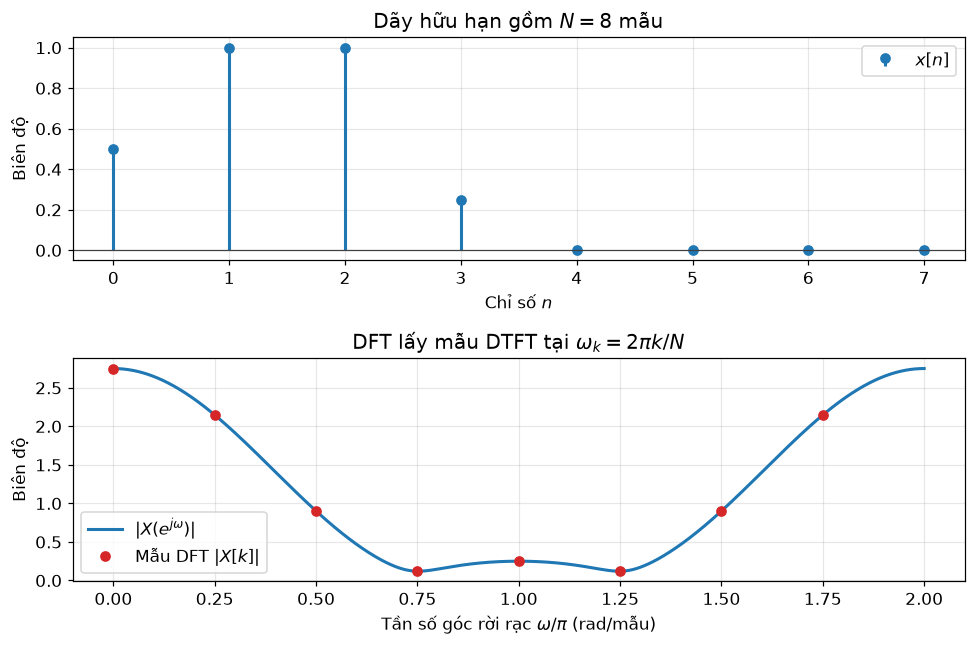

DFT trực tiếp và FFT bằng nhau: True
IFFT tái tạo lại dãy đầu vào: True


In [2]:
# Tạo dãy hữu hạn x[n], với n bắt đầu tại 0 theo quy ước DFT.
x = np.array([0.5, 1.0, 1.0, 0.25, 0.0, 0.0, 0.0, 0.0])
N = len(x)
n = np.arange(N)
omega_dense = np.linspace(0, 2 * np.pi, 2_001)
omega_k = 2 * np.pi * np.arange(N) / N

# Tính DTFT liên tục theo omega, DFT trực tiếp và FFT.
X_dtft = dtft_finite(x, omega_dense)
X_at_bins = dtft_finite(x, omega_k)
X_direct = dft_direct(x)
X_fft = np.fft.fft(x)
assert np.allclose(X_at_bins, X_direct)
assert np.allclose(X_direct, X_fft)
assert np.allclose(np.fft.ifft(X_fft), x)

# Vẽ dãy đầu vào và các mẫu DFT đặt trên đường DTFT.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], n, x, label=r"$x[n]$", color="C0")
axes[0].set_title("Dãy hữu hạn gồm $N=8$ mẫu")

axes[1].plot(omega_dense / np.pi, np.abs(X_dtft), label=r"$|X(e^{j\omega})|$")
axes[1].plot(omega_k / np.pi, np.abs(X_fft), "o", color="C3", label=r"Mẫu DFT $|X[k]|$")
axes[1].set_xlabel(r"Tần số góc rời rạc $\omega/\pi$ (rad/mẫu)")
axes[1].set_ylabel("Biên độ")
axes[1].set_title(r"DFT lấy mẫu DTFT tại $\omega_k=2\pi k/N$")
axes[1].legend()
fig.tight_layout()
plt.show()

print("DFT trực tiếp và FFT bằng nhau:", np.allclose(X_direct, X_fft))
print("IFFT tái tạo lại dãy đầu vào:", np.allclose(np.fft.ifft(X_fft), x))

**Nhận xét:** Đường liền là DTFT, còn tám marker là DFT. FFT tính đúng tám giá trị DFT này, không tính toàn bộ hàm DTFT liên tục. Trong `np.fft.fft`, hệ số $1/N$ nằm ở `np.fft.ifft`, phù hợp với công thức DFT ngược ở trên.

## Minh họa 2: Thứ tự mặc định và `fftshift`

`np.fft.fft` trả các mẫu theo thứ tự tần số $0,2\pi/N,\ldots,2\pi(N-1)/N$. Các mẫu ở nửa sau tương ứng với tần số âm khi quy về một chu kỳ $[-\pi,\pi)$. Để vẽ phổ hai phía trực quan, cần dịch **cả** phổ và trục tần số:

```python
X_shifted = np.fft.fftshift(X)
omega_shifted = np.fft.fftshift(omega)
```

`fftshift` chỉ sắp xếp lại thứ tự hiển thị, không làm thay đổi các giá trị phổ.

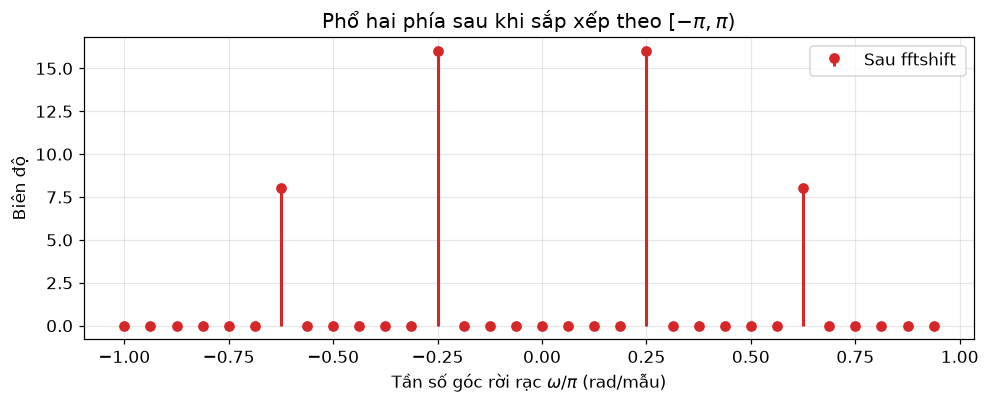

In [3]:
# Tạo một dãy gồm hai thành phần hình sin khớp các điểm DFT.
N = 32
n = np.arange(N)
x_tones = np.cos(0.25 * np.pi * n) + 0.5 * np.cos(0.625 * np.pi * n)
X_tones = np.fft.fft(x_tones)
omega = 2 * np.pi * np.fft.fftfreq(N, d=1)

# Sắp xếp lại cùng phổ này để tần số 0 ở giữa.
X_shifted = np.fft.fftshift(X_tones)
omega_shifted = np.fft.fftshift(omega)

fig, ax = plt.subplots(figsize=(9, 3.8))
stem_spectrum(ax, omega_shifted, X_shifted, label=r"Sau $\operatorname{fftshift}$", color="C3")
ax.set_title(r"Phổ hai phía sau khi sắp xếp theo $[-\pi,\pi)$")
fig.tight_layout()
plt.show()

**Nhận xét:** `np.fft.fft` ban đầu đặt các mẫu tần số âm ở cuối mảng. Hình trên dùng `fftshift` để đưa tần số âm sang bên trái, tần số dương sang bên phải và tần số $0$ về giữa. Khi dùng `fftshift`, phải dịch đồng thời `X` và `omega`; nếu chỉ dịch phổ thì trục tần số sẽ sai.

## Minh họa 3: Đọc các thành phần hình sin từ DFT

Với dãy ở Minh họa 2,

$$
x[n]=\cos\left(\frac{\pi}{4}n\right)+0.5\cos\left(\frac{5\pi}{8}n\right),
\qquad 0\leq n\leq31,
$$

hai tần số thành phần đúng bằng các điểm DFT:

$$
\frac{\pi}{4}=\frac{2\pi}{32}\cdot4,
\qquad
\frac{5\pi}{8}=\frac{2\pi}{32}\cdot10.
$$

Vì thế, phổ có các mẫu nổi bật tại $\pm\pi/4$ và $\pm5\pi/8$.

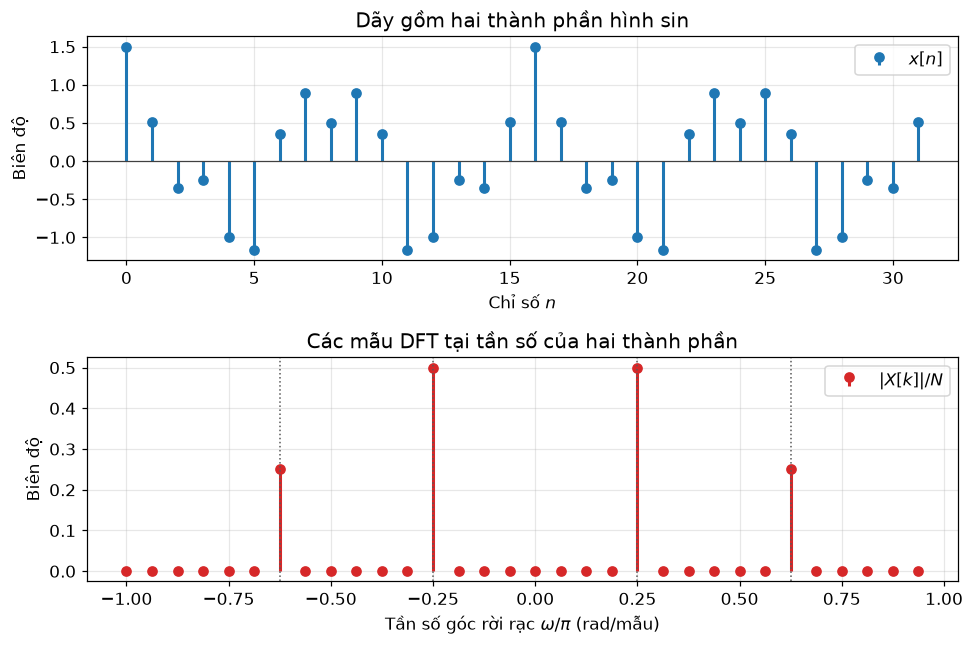

Bốn tần số có biên độ DFT lớn nhất (đơn vị π rad/mẫu):
[-0.625 -0.25   0.25   0.625]


In [4]:
# Chuẩn hóa DFT theo N để so sánh độ lớn các thành phần.
X_normalized = X_shifted / N

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], n, x_tones, label=r"$x[n]$", color="C0")
axes[0].set_title("Dãy gồm hai thành phần hình sin")

stem_spectrum(axes[1], omega_shifted, X_normalized, label=r"$|X[k]|/N$", color="C3")
for omega_0 in [-0.625 * np.pi, -0.25 * np.pi, 0.25 * np.pi, 0.625 * np.pi]:
    axes[1].axvline(omega_0 / np.pi, color="0.35", linestyle=":", linewidth=1.0)
axes[1].set_title("Các mẫu DFT tại tần số của hai thành phần")
fig.tight_layout()
plt.show()

peak_indices = np.argsort(np.abs(X_normalized))[-4:]
print("Bốn tần số có biên độ DFT lớn nhất (đơn vị π rad/mẫu):")
print(np.sort(omega_shifted[peak_indices] / np.pi))

**Nhận xét:** Vì dãy là thực, các mẫu DFT có đối xứng liên hợp; do đó mỗi thành phần hình sin thực xuất hiện thành một cặp tần số dương và âm. Phép chuẩn hóa $|X[k]|/N$ chỉ thuận tiện cho việc đọc độ lớn; nó không thay đổi vị trí các mẫu phổ.

## Minh họa 4: Zero-padding để vẽ phổ dày hơn

Ta xét lại một dãy hữu hạn $x[n]$ dài $N$ mẫu. Thay vì tính FFT $N$ điểm, ta kéo dài dãy thành $M>N$ mẫu bằng cách thêm các số $0$ ở cuối:

$$
x_M[n] =
\begin{cases}
x[n], & 0\leq n\leq N-1,\\
0, & N\leq n\leq M-1.
\end{cases}
$$

FFT $M$ điểm lấy mẫu cùng DTFT tại các điểm dày hơn, với khoảng cách

$$
\Delta\omega=\frac{2\pi}{M}.
$$

Vì vậy, các mẫu FFT có thể được nối lại để vẽ phổ của dãy rời rạc mịn hơn.

**Python cần biết:** Tham số `n=M` trong `np.fft.fft(x, n=M)` đặt độ dài biến đổi là $M$. Khi $M$ lớn hơn độ dài của `x`, NumPy tự thêm các số $0$ ở cuối dãy trước khi tính FFT.

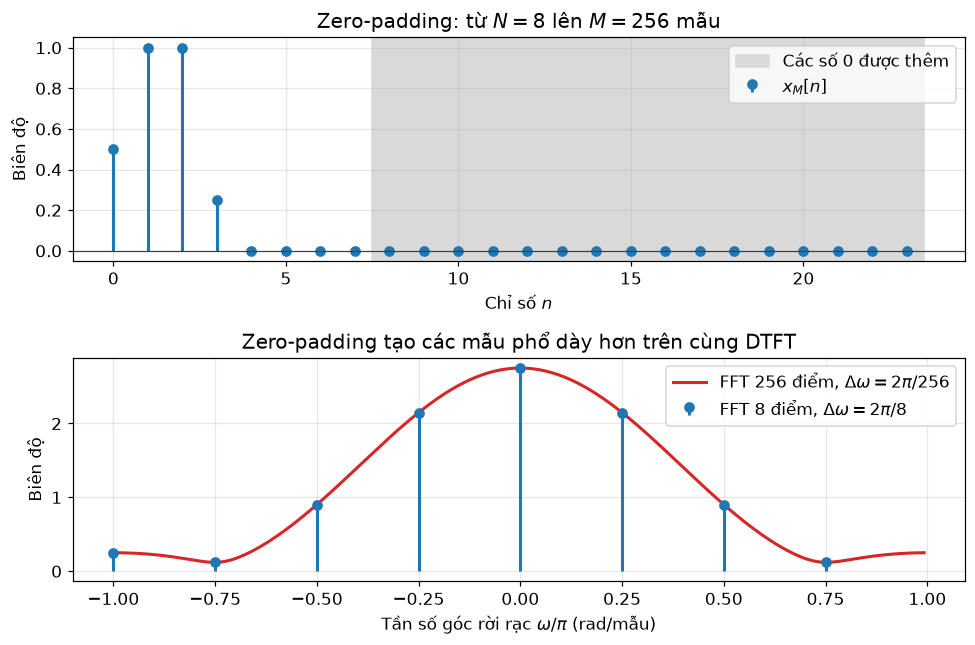

Các mẫu FFT gốc nằm trong FFT đã zero-padding: True


In [5]:
# Tạo một dãy 8 mẫu và phiên bản zero-padding đến 256 mẫu.
x_zero = np.array([0.5, 1.0, 1.0, 0.25, 0.0, 0.0, 0.0, 0.0])
N_zero = len(x_zero)
M_zero = 256
x_padded = np.zeros(M_zero)
x_padded[:N_zero] = x_zero

# Tính FFT gốc và FFT sau zero-padding.
X_original = np.fft.fft(x_zero)
X_padded = np.fft.fft(x_zero, n=M_zero)
omega_original = 2 * np.pi * np.fft.fftfreq(N_zero, d=1)
omega_padded = 2 * np.pi * np.fft.fftfreq(M_zero, d=1)

# Các mẫu gốc xuất hiện nguyên vẹn trong FFT đã zero-padding.
step = M_zero // N_zero
assert np.allclose(X_padded[::step], X_original)

# Sắp xếp phổ hai phía để vẽ.
X_original_shifted = np.fft.fftshift(X_original)
omega_original_shifted = np.fft.fftshift(omega_original)
X_padded_shifted = np.fft.fftshift(X_padded)
omega_padded_shifted = np.fft.fftshift(omega_padded)

# Vẽ dãy đã thêm số 0 và các mẫu phổ thưa/dày.
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)
stem_sequence(axes[0], np.arange(24), x_padded[:24], label=r"$x_M[n]$", color="C0")
axes[0].axvspan(N_zero - 0.5, 23.5, color="0.85", label="Các số 0 được thêm")
axes[0].set_title(rf"Zero-padding: từ $N={N_zero}$ lên $M={M_zero}$ mẫu")
axes[0].legend()

axes[1].plot(
    omega_padded_shifted / np.pi,
    np.abs(X_padded_shifted),
    color="C3",
    label=rf"FFT {M_zero} điểm, $\Delta\omega=2\pi/{M_zero}$",
)
stem_spectrum(
    axes[1], omega_original_shifted, X_original_shifted,
    label=rf"FFT {N_zero} điểm, $\Delta\omega=2\pi/{N_zero}$", color="C0",
)
axes[1].set_title("Zero-padding tạo các mẫu phổ dày hơn trên cùng DTFT")
axes[1].legend()
fig.tight_layout()
plt.show()

print("Các mẫu FFT gốc nằm trong FFT đã zero-padding:", np.allclose(X_padded[::step], X_original))

**Nhận xét:** Zero-padding không thêm thông tin mới vào dãy ban đầu và không làm búp chính hẹp hơn. Nó chỉ làm khoảng cách giữa các mẫu phổ giảm từ $2\pi/N$ xuống $2\pi/M$. Vì vậy, FFT sau zero-padding là một cách thực dụng để vẽ đường DTFT của dãy hữu hạn bằng các mẫu rất gần nhau.

## Câu hỏi suy ngẫm

1. Với dãy dài $N$, DFT lấy mẫu DTFT tại các tần số $\omega_k$ nào?
2. Vì sao `np.fft.fft(x)` và `np.fft.ifft(X)` có quy ước chuẩn hóa khác nhau?
3. Khi vẽ phổ hai phía, vì sao phải dùng `fftshift` đồng thời cho phổ và trục tần số?
4. Nếu một thành phần hình sin không đúng bằng một điểm DFT, các mẫu DFT lân cận sẽ thay đổi thế nào?
5. Zero-padding thay đổi số mẫu phổ hiển thị, nhưng có thay đổi dãy đầu vào đã quan sát hay không?